# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [1]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [3]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [4]:
print("1. До set_seed():")
for i in range(2):
    numbers = list(range(10))
    number = random.randint(1, 100)
    random.shuffle(numbers)
    print(f"Спроба {i + 1}: число = {number}, список = {numbers}")

print("\n2. З однаковим seed перед кожною спробою:")
for i in range(2):
    set_seed()
    numbers = list(range(10))
    number = random.randint(1, 100)
    random.shuffle(numbers)
    print(f"Спроба {i + 1}: число = {number}, список = {numbers}")

print("\n3. Без проміжного скидання seed:")
set_seed()
for i in range(2):
    numbers = list(range(10))
    number = random.randint(1, 100)
    random.shuffle(numbers)
    print(f"Спроба {i + 1}: число = {number}, список = {numbers}")

1. До set_seed():
Спроба 1: число = 77, список = [2, 6, 3, 1, 9, 8, 0, 5, 7, 4]
Спроба 2: число = 38, список = [3, 0, 1, 9, 7, 8, 2, 4, 5, 6]

2. З однаковим seed перед кожною спробою:
Спроба 1: число = 82, список = [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Спроба 2: число = 82, список = [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]

3. Без проміжного скидання seed:
Спроба 1: число = 82, список = [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Спроба 2: число = 76, список = [4, 3, 2, 9, 5, 1, 7, 8, 0, 6]


Висновок: без скидання seed результати послідовних спроб
можуть відрізнятися. Виклик set_seed() з однаковим значенням
перед кожною спробою відновлює початковий стан генератора,
тому число та перестановка списку повторюються.

Якщо встановити seed лише один раз, наступні виклики
продовжують послідовність генератора. Отже, seed забезпечує
відтворюваність усієї послідовності, а не однаковість усіх чисел.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [5]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [6]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [7]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print("Масив нулів:")
print(zeros_arr)
print("Форма:", zeros_arr.shape)
print("Тип даних:", zeros_arr.dtype)

print("\nМасив сімок:")
print(sevens_arr)
print("Форма:", sevens_arr.shape)
print("Тип даних:", sevens_arr.dtype)

Масив нулів:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
Форма: (3, 4)
Тип даних: float64

Масив сімок:
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]]
Форма: (3, 4)
Тип даних: int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [8]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print("Масив із кроком 2:", arange_arr)
print("П’ять рівномірних точок:", linspace_arr)

Масив із кроком 2: [ 0  2  4  6  8 10 12 14 16 18]
П’ять рівномірних точок: [0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [9]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print("Одинична матриця:")
print(identity)
print("Кількість вимірів:", identity.ndim)

print("\nВипадкові цілі числа:")
print(random_ints)
print("Кількість вимірів:", random_ints.ndim)

Одинична матриця:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Кількість вимірів: 2

Випадкові цілі числа:
[[6 3 7]
 [4 6 9]
 [2 6 7]]
Кількість вимірів: 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [10]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean)
print("Стандартне відхилення:", std)
print("Z-scores:", z_scores)

Середнє: 81.1
Стандартне відхилення: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [11]:
arr = np.arange(1, 13)

matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print("Матриця:")
print(matrix)
print("Сума по рядках:", row_sums)
print("Сума по стовпцях:", col_sums)

Матриця:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках: [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [12]:
df = pd.DataFrame({
    "name": ["Богдан", "Юрій", "Анна", "Олена", "Максим"],
    "score": [85, 72, 95, 80, 91]
})

top = df[df["score"] > 80].sort_values(
    by="score", ascending=False
)

print(top)

     name  score
2    Анна     95
4  Максим     91
0  Богдан     85


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [13]:
df["grade"] = np.where(
    df["score"] >= 90, "A",
    np.where(df["score"] >= 75, "B", "C")
)

print(df)

     name  score grade
0  Богдан     85     B
1    Юрій     72     C
2    Анна     95     A
3   Олена     80     B
4  Максим     91     A


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [14]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print("Тензор нулів:")
print(zeros_t)
print("Форма:", zeros_t.shape)
print("Тип даних:", zeros_t.dtype)

print("\nТензор сімок:")
print(sevens_t)
print("Форма:", sevens_t.shape)
print("Тип даних:", sevens_t.dtype)

Тензор нулів:
tensor([[0., 0., 0.],
        [0., 0., 0.]])
Форма: torch.Size([2, 3])
Тип даних: torch.float32

Тензор сімок:
tensor([[7, 7, 7],
        [7, 7, 7]])
Форма: torch.Size([2, 3])
Тип даних: torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [15]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print("Тензор із кроком 2:")
print(arange_t)

print("\nП’ять рівномірних точок:")
print(linspace_t)

Тензор із кроком 2:
tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])

П’ять рівномірних точок:
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [16]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print("Тензор зі списку:")
print(from_list)
print("Форма:", from_list.shape)
print("Тип даних:", from_list.dtype)
print("Кількість вимірів:", from_list.ndim)

print("\nВипадковий тензор:")
print(random_t)
print("Форма:", random_t.shape)
print("Тип даних:", random_t.dtype)
print("Кількість вимірів:", random_t.ndim)

Тензор зі списку:
tensor([[1, 2],
        [3, 4]])
Форма: torch.Size([2, 2])
Тип даних: torch.int64
Кількість вимірів: 2

Випадковий тензор:
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
Форма: torch.Size([3, 3])
Тип даних: torch.float32
Кількість вимірів: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [17]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

print("Автоматичний градієнт:", x.grad.item())
print("Аналітичний градієнт:", 2 * n)

Автоматичний градієнт: 10.0
Аналітичний градієнт: 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [18]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for step in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()

    with torch.no_grad():
        x -= lr * x.grad

    x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")

x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

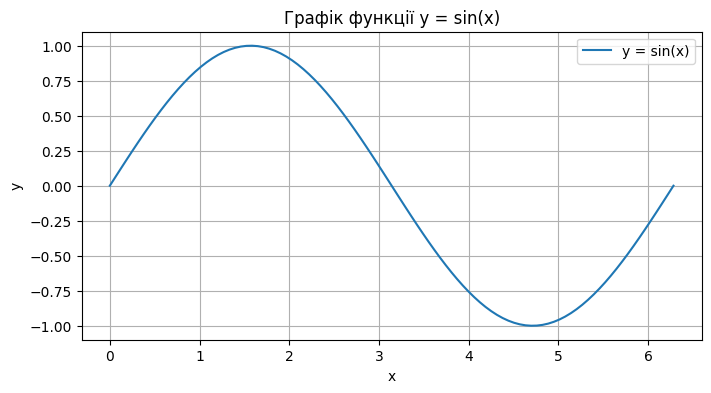

In [19]:
xs = np.linspace(0, 2 * np.pi, 100)

plt.figure(figsize=(8, 4))
plt.plot(xs, np.sin(xs), label="y = sin(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Графік функції y = sin(x)")
plt.grid(True)
plt.legend()
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

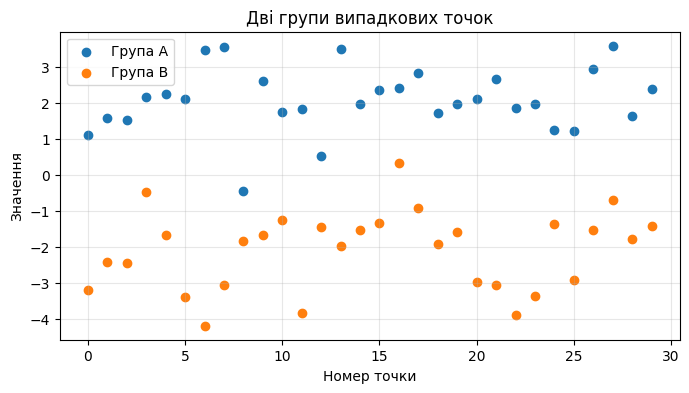

In [20]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.figure(figsize=(8, 4))
plt.scatter(np.arange(30), group_a, color="C0", label="Група A")
plt.scatter(np.arange(30), group_b, color="C1", label="Група B")
plt.xlabel("Номер точки")
plt.ylabel("Значення")
plt.title("Дві групи випадкових точок")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [21]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

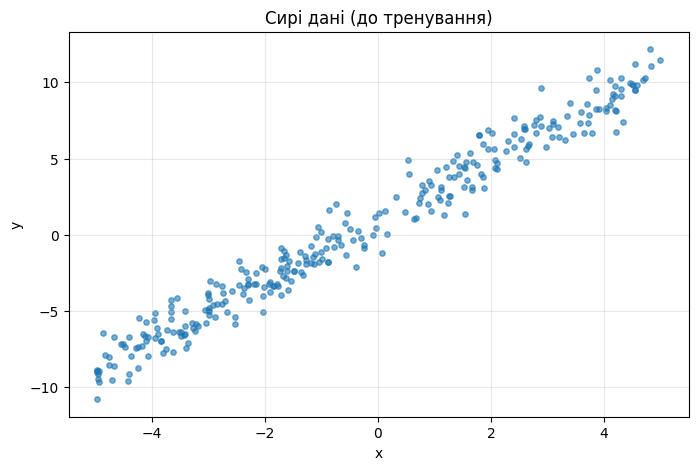

In [22]:
plt.figure(figsize=(8, 5))
plt.scatter(x1.numpy(), y1.numpy(), s=15, alpha=0.6)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Сирі дані (до тренування)")
plt.grid(alpha=0.3)
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [23]:
indices = torch.randperm(TASK1_N)

train_end = int(0.70 * TASK1_N)
val_end = train_end + int(0.15 * TASK1_N)

train_idx = indices[:train_end]
val_idx = indices[train_end:val_end]
test_idx = indices[val_end:]

x_train1, y_train1 = x1[train_idx], y1[train_idx]
x_val1, y_val1 = x1[val_idx], y1[val_idx]
x_test1, y_test1 = x1[test_idx], y1[test_idx]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")

train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [24]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


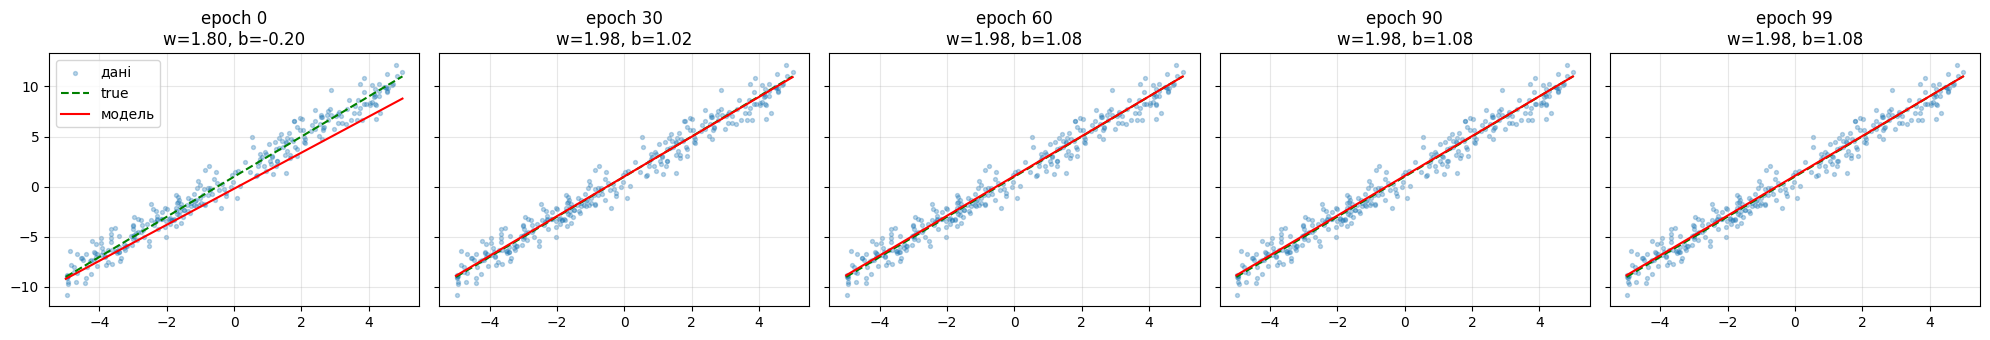

In [25]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Власний сценарій: вартість абонемента в спортзал

Досліджую залежність загальної вартості абонемента
від кількості місяців відвідування.

x — кількість місяців, від 1 до 12.
y — загальна вартість у євро.

Використовую залежність y = 25x + 20 + ε:                           

w = 25 — умовна щомісячна плата;

b = 20 — одноразовий вступний внесок;

ε — випадковий шум із середнім 0 та стандартним відхиленням

5 євро, який умовно відображає невеликі знижки або доплати.

Значення обрані для навчального прикладу.
Дані синтетичні й не відображають тарифи конкретного спортзалу.

Мета — навчити лінійну регресію визначати залежність
вартості від кількості місяців і перевірити її
на тестовій вибірці.

In [26]:
set_seed()

GYM_TRUE_W = 25.0
GYM_TRUE_B = 20.0
GYM_N = 300

gym_months = torch.randint(1, 13, (GYM_N, 1)).float()
gym_noise = 5.0 * torch.randn(GYM_N, 1)
gym_cost = GYM_TRUE_W * gym_months + GYM_TRUE_B + gym_noise

gym_df = pd.DataFrame({
    "months": gym_months.squeeze(1).numpy().astype(int),
    "total_cost_eur": gym_cost.squeeze(1).numpy()
})

csv_path = os.path.join(ARTIFACT_DIR, "dataset.csv")
gym_df.to_csv(csv_path, index=False)

print(gym_df.head())
print("\nКількість записів:", len(gym_df))
print("CSV збережено:", csv_path)

   months  total_cost_eur
0       7      192.214066
1      12      315.158264
2       5      149.356400
3      11      294.521790
4       7      197.019012

Кількість записів: 300
CSV збережено: /content/drive/MyDrive/ai_systems/lab1/dataset.csv


In [27]:
def split_data(x, y, train_ratio=0.70, val_ratio=0.15):
    indices = torch.randperm(len(x))

    train_end = int(len(x) * train_ratio)
    val_end = train_end + int(len(x) * val_ratio)

    train_idx = indices[:train_end]
    val_idx = indices[train_end:val_end]
    test_idx = indices[val_end:]

    return (
        x[train_idx], y[train_idx],
        x[val_idx], y[val_idx],
        x[test_idx], y[test_idx]
    )


set_seed()

(
    gym_x_train, gym_y_train,
    gym_x_val, gym_y_val,
    gym_x_test, gym_y_test
) = split_data(gym_months, gym_cost)

print(
    f"train/val/test: "
    f"{len(gym_x_train)}/{len(gym_x_val)}/{len(gym_x_test)}"
)

train/val/test: 210/45/45


In [28]:
def evaluate_model(model, x, y):
    model.eval()
    with torch.no_grad():
        predictions = model(x)
        mse = torch.nn.functional.mse_loss(predictions, y).item()
        mae = torch.nn.functional.l1_loss(predictions, y).item()
    return mse, mae


def train_model(x_train, y_train, x_val, y_val,
                epochs=3000, lr=0.01):
    model = torch.nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    history = {"train": [], "val": []}

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        loss = loss_fn(model(x_train), y_train)
        loss.backward()
        optimizer.step()

        train_mse, _ = evaluate_model(model, x_train, y_train)
        val_mse, _ = evaluate_model(model, x_val, y_val)
        history["train"].append(train_mse)
        history["val"].append(val_mse)

        if (epoch + 1) % 500 == 0:
            print(
                f"Епоха {epoch + 1}: "
                f"train MSE = {train_mse:.3f}, "
                f"val MSE = {val_mse:.3f}"
            )

    return model, history


set_seed()

gym_model, gym_history = train_model(
    gym_x_train, gym_y_train,
    gym_x_val, gym_y_val
)

print(f"\nw = {gym_model.weight.item():.3f} (задано 25)")
print(f"b = {gym_model.bias.item():.3f} (задано 20)")

Епоха 500: train MSE = 25.382, val MSE = 18.550
Епоха 1000: train MSE = 24.349, val MSE = 17.907
Епоха 1500: train MSE = 24.330, val MSE = 17.936
Епоха 2000: train MSE = 24.329, val MSE = 17.942
Епоха 2500: train MSE = 24.329, val MSE = 17.943
Епоха 3000: train MSE = 24.329, val MSE = 17.943

w = 25.062 (задано 25)
b = 20.594 (задано 20)


In [29]:
test_mse, test_mae = evaluate_model(
    gym_model, gym_x_test, gym_y_test
)

print(f"Тестова MSE: {test_mse:.3f}")
print(f"Тестова RMSE: {test_mse ** 0.5:.3f} євро")
print(f"Тестова MAE: {test_mae:.3f} євро")
print("Кількість тестових прикладів:", len(gym_x_test))

Тестова MSE: 28.301
Тестова RMSE: 5.320 євро
Тестова MAE: 4.292 євро
Кількість тестових прикладів: 45


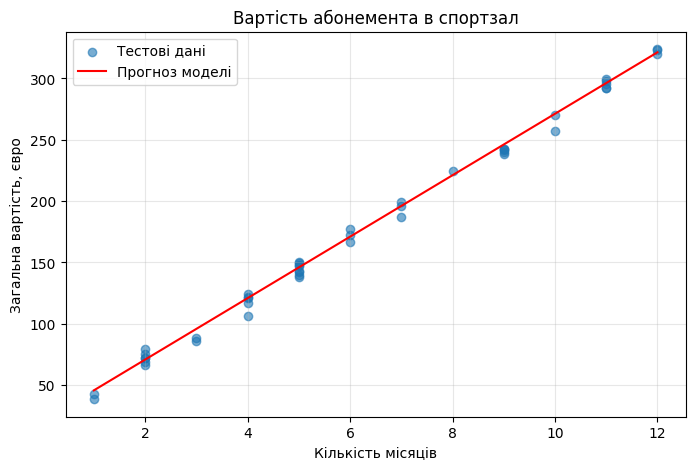

In [30]:
months_line = torch.linspace(1, 12, 100).reshape(-1, 1)

with torch.no_grad():
    predicted_cost = gym_model(months_line)

plt.figure(figsize=(8, 5))
plt.scatter(
    gym_x_test.numpy(),
    gym_y_test.numpy(),
    alpha=0.6,
    label="Тестові дані"
)
plt.plot(
    months_line.numpy(),
    predicted_cost.numpy(),
    color="red",
    label="Прогноз моделі"
)
plt.xlabel("Кількість місяців")
plt.ylabel("Загальна вартість, євро")
plt.title("Вартість абонемента в спортзал")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [31]:
model_path = os.path.join(ARTIFACT_DIR, "model.pt")

torch.save(gym_model.state_dict(), model_path)

print("Модель збережено:", model_path)

Модель збережено: /content/drive/MyDrive/ai_systems/lab1/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [32]:
!pip install -q gradio

import gradio as gr

In [33]:
loaded_model = torch.nn.Linear(1, 1)
loaded_model.load_state_dict(
    torch.load(model_path, map_location="cpu", weights_only=True)
)
loaded_model.eval()


def predict_gym_cost(months):
    x = torch.tensor([[float(months)]], dtype=torch.float32)

    with torch.no_grad():
        cost = loaded_model(x).item()

    return round(cost, 2)


demo = gr.Interface(
    fn=predict_gym_cost,
    inputs=gr.Slider(
        minimum=1,
        maximum=12,
        step=1,
        value=6,
        label="Кількість місяців"
    ),
    outputs=gr.Number(label="Прогноз загальної вартості, євро"),
    title="Вартість абонемента в спортзал",
    description="Навчальний приклад на синтетичних даних."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://840baf7099797a9185.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```